Specificity of this file:
We will train on quotes, test on trades, for both prices and implied vol.

In [145]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pytz

## DATA LOADING

In [146]:
project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

from quantdata.massive.client import MassiveClient


def test():

    ticker = "SPY"
    d = date(2024, 1, 3)
    client = MassiveClient()
    option_ticker = "O:SPY240105P00470000"

    def package(ticker, verbose=Context.all):

        with verbose.write_t(
            f"Fetching OCV, trades, quotes for {ticker} on {fmt_date(d)}... ", end=""
        ) as tme:
            ocv = client.fetch_day_summary(ticker, d, adjusted=True)
            verbose.write(f"done: found {fmt_dict(ocv)}. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching trades for {ticker} on {fmt_date(d)}... ", end="") as tme:
            trades = client.fetch_trades(ticker, d)
            verbose.write(f"done: found {len(trades)} trades. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching quotes for {ticker} on {fmt_date(d)}... ", end="") as tme:
            quotes = client.fetch_quotes(ticker, d)
            verbose.write(f"done: found {len(quotes)} quotes. This took {tme}.", head=False)

        return ocv, trades, quotes

    package(ticker)
    ocv, trades, quotes = package(option_ticker)

    display(ocv)
    display(trades.head())
    display(quotes.head())


test()

00: Fetching OCV, trades, quotes for SPY on 2024-01-03... done: found open: 470.43, close: 468.79, volume: 103577866.0, high: 471.19, low: 468.17, afterHours: 469.35, preMarket: 472.07 and adjusted: True. This took 0.566ms.
00: Fetching trades for SPY on 2024-01-03... done: found 656589 trades. This took 0.01s.
00: Fetching quotes for SPY on 2024-01-03... done: found 4927896 quotes. This took 0.034s.
00: Fetching OCV, trades, quotes for O:SPY240105P00470000 on 2024-01-03... done: found open: 1.67, close: 2.38, volume: 69357.0, high: 2.71, low: 1.25, afterHours: 2.43, preMarket: 1.67 and adjusted: True. This took 0.675ms.
00: Fetching trades for O:SPY240105P00470000 on 2024-01-03... done: found 8895 trades. This took 1.55ms.
00: Fetching quotes for O:SPY240105P00470000 on 2024-01-03... done: found 85145 quotes. This took 3.38ms.


{'open': 1.67,
 'close': 2.38,
 'volume': 69357.0,
 'high': 2.71,
 'low': 1.25,
 'afterHours': 2.43,
 'preMarket': 1.67,
 'adjusted': True}

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.424 EST,1.67,1.0,256
2024-01-03 09:30:00.472 EST,1.69,4.0,64
2024-01-03 09:30:00.576 EST,1.7,10.0,64
2024-01-03 09:30:00.617 EST,1.71,1.0,576
2024-01-03 09:30:01.480 EST,1.71,1.0,256


ts_ns,bid_price,bid_size,ask_price,ask_size
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.217322240 EST,1.72,46.0,1.74,46.0
2024-01-03 09:30:00.383298048 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.400694528 EST,1.69,2.0,1.8,36.0
2024-01-03 09:30:00.419033088 EST,1.67,80.0,1.8,36.0


In [147]:
option_ticker = "O:SPY240105P00470000"

In [148]:
client = MassiveClient()
df_quotes = client.fetch_quotes(option_ticker, date(2024, 1, 3))
df_quotes

ts_ns,bid_price,bid_size,ask_price,ask_size
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.217322240 EST,1.72,46.0,1.74,46.0
2024-01-03 09:30:00.383298048 EST,1.71,62.0,1.75,62.0
2024-01-03 09:30:00.400694528 EST,1.69,2.0,1.8,36.0
2024-01-03 09:30:00.419033088 EST,1.67,80.0,1.8,36.0
…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,2.35,38.0,2.37,123.0
2024-01-03 16:14:42.450262016 EST,2.35,41.0,2.37,93.0
2024-01-03 16:14:54.333178624 EST,2.36,70.0,2.38,30.0


In [149]:
df_trades = client.fetch_trades(option_ticker, date(2024, 1, 3))

In [150]:
df_trades

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.424 EST,1.67,1.0,256
2024-01-03 09:30:00.472 EST,1.69,4.0,64
2024-01-03 09:30:00.576 EST,1.7,10.0,64
2024-01-03 09:30:00.617 EST,1.71,1.0,576
2024-01-03 09:30:01.480 EST,1.71,1.0,256
…,…,…,…
2024-01-03 16:11:20.628 EST,2.37,72.0,2624
2024-01-03 16:11:20.628 EST,2.37,72.0,2624
2024-01-03 16:12:51.108 EST,2.38,1.0,2624


In [151]:
df_trades.head()

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.424 EST,1.67,1.0,256
2024-01-03 09:30:00.472 EST,1.69,4.0,64
2024-01-03 09:30:00.576 EST,1.7,10.0,64
2024-01-03 09:30:00.617 EST,1.71,1.0,576
2024-01-03 09:30:01.480 EST,1.71,1.0,256


In [152]:
df_spy = client.fetch_trades("SPY", date(2024, 1, 3))
df_spy.head()

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 04:00:00.023728896 EST,472.04,4.0,73728
2024-01-03 04:00:00.033502208 EST,472.43,16.0,73728
2024-01-03 04:00:00.035570944 EST,472.36,1.0,73728
2024-01-03 04:00:00.035577088 EST,472.31,4.0,73728
2024-01-03 04:00:00.370607616 EST,472.16,2.0,73728


In [153]:
from quantdata.massive.trade_conds import NORMAL_TRADE_EXCLUDE_FLAGS


def filter_df(df, col="trade_code"):
    return df.filter((pl.col(col) & int(NORMAL_TRADE_EXCLUDE_FLAGS)) == 0)

In [154]:
df_trades = filter_df(df_trades)
df_spy = filter_df(df_spy)

# Merging with time Lag

In [155]:
quotes_for_join = df_quotes.rename({"ts_ns": "quote_ts_ns"})

df_trade_spread = df_trades.join_asof(
    quotes_for_join.sort("quote_ts_ns"),
    left_on="ts_ns",
    right_on="quote_ts_ns",
    strategy="backward",
)

df_trade_spread = df_trade_spread.with_columns(
    (pl.col("ts_ns") - pl.col("quote_ts_ns")).alias("quote_age")
)

In [156]:
df_trade_spread

ts_ns,price,size,trade_code,quote_ts_ns,bid_price,bid_size,ask_price,ask_size,quote_age
"datetime[ns, America/New_York]",f64,f64,u32,"datetime[ns, America/New_York]",f64,f64,f64,f64,duration[ns]
2024-01-03 09:30:00.424 EST,1.67,1.0,256,2024-01-03 09:30:00.419033088 EST,1.67,80.0,1.8,36.0,4966912ns
2024-01-03 09:30:00.472 EST,1.69,4.0,64,2024-01-03 09:30:00.470255104 EST,1.64,80.0,1.8,36.0,1744896ns
2024-01-03 09:30:00.576 EST,1.7,10.0,64,2024-01-03 09:30:00.573615872 EST,1.7,54.0,1.72,40.0,2384128ns
2024-01-03 09:30:00.617 EST,1.71,1.0,576,2024-01-03 09:30:00.573615872 EST,1.7,54.0,1.72,40.0,43384128ns
2024-01-03 09:30:01.480 EST,1.71,1.0,256,2024-01-03 09:30:01.019511808 EST,1.7,54.0,1.72,40.0,460488192ns
…,…,…,…,…,…,…,…,…,…
2024-01-03 16:11:20.628 EST,2.37,72.0,2624,2024-01-03 16:11:20.520283392 EST,2.39,27.0,2.4,37.0,107716608ns
2024-01-03 16:11:20.628 EST,2.37,72.0,2624,2024-01-03 16:11:20.520283392 EST,2.39,27.0,2.4,37.0,107716608ns
2024-01-03 16:12:51.108 EST,2.38,1.0,2624,2024-01-03 16:12:42.623446272 EST,2.36,85.0,2.39,110.0,8s 484553728ns


In [157]:
(df_trade_spread.select("bid_size") == 0).sum()

bid_size
u32
0


In [158]:
quote_events = df_quotes.with_columns(
    [
        pl.lit("quote").alias("event_type"),
        (
            (pl.col("ask_size") * pl.col("bid_price") + pl.col("bid_size") * pl.col("ask_price"))
            / (pl.col("bid_size") + pl.col("ask_size"))
        ).alias("observed_price"),
        (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
    ]
)

TRADE_LAG_NS = 250_000_000  # 250 ms in nanoseconds

trade_events = (
    df_trades.with_columns(
        # shift trade timestamp forward for the asof join
        (pl.col("ts_ns") + pl.duration(nanoseconds=TRADE_LAG_NS)).alias("ts_lagged")
    )
    .join_asof(
        df_quotes.rename({"ts_ns": "quote_ts_ns"}).sort("quote_ts_ns"),
        left_on="ts_lagged",  # <-- use lagged time for matching
        right_on="quote_ts_ns",
        strategy="backward",
    )
    .drop(
        "ts_lagged"  # drop the helper column, keep original ts_ns
    )
    .with_columns(
        [
            pl.lit("trade").alias("event_type"),
            pl.col("price").alias("observed_price"),
            (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
        ]
    )
)


# trade_events = df_trades.join_asof(
#     df_quotes.rename({"ts_ns": "quote_ts_ns"}).sort("quote_ts_ns"),
#     left_on="ts_ns",
#     right_on="quote_ts_ns",
#     strategy="backward",
# ).with_columns(
#     [
#         pl.lit("trade").alias("event_type"),
#         pl.col("price").alias("observed_price"),
#         (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
#     ]
# )

In [159]:
events = pl.concat(
    [
        quote_events.select(
            [
                "ts_ns",
                "event_type",
                "observed_price",
                "spread",
                "bid_price",
                "ask_price",
                "bid_size",
                "ask_size",
            ]
        ),
        trade_events.select(
            [
                "ts_ns",
                "event_type",
                "observed_price",
                "spread",
                "bid_price",
                "ask_price",
                "bid_size",
                "ask_size",
            ]
        ),
    ]
).sort("ts_ns")

In [160]:
events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0
…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0


In [161]:
events = events.drop_nans()

In [162]:
# ── CONFIG ──────────────────────────────────────────────────────────────────
ONE_SIDED_R_MULTIPLIER = 10.0  # inflate variance for one-sided quotes
TRADE_R_DIVISOR = 4.0  # trades are more trusted than quotes
STALE_QUOTE_THRESHOLD = 60_000  # ms — mark quote as stale beyond this


# ── 1. PROCESS QUOTES ───────────────────────────────────────────────────────
def process_quotes(df_quotes: pl.DataFrame) -> pl.DataFrame:
    """
    Input columns expected: ts_ns, bid, ask, bid_size, ask_size
    Zeros are treated as missing.
    """
    df = (
        df_quotes.with_columns(
            [
                # treat 0 as null
                pl.when(pl.col("bid_price") <= 0)
                .then(None)
                .otherwise(pl.col("bid_price"))
                .alias("bid_price"),
                pl.when(pl.col("ask_price") <= 0)
                .then(None)
                .otherwise(pl.col("ask_price"))
                .alias("ask_price"),
                pl.when(pl.col("bid_size") <= 0)
                .then(None)
                .otherwise(pl.col("bid_size"))
                .alias("bid_size"),
                pl.when(pl.col("ask_size") <= 0)
                .then(None)
                .otherwise(pl.col("ask_size"))
                .alias("ask_size"),
            ]
        )
        .with_columns(
            [
                # classify quote side
                pl.when(pl.col("bid_price").is_not_null() & pl.col("ask_price").is_not_null())
                .then(pl.lit("two_sided"))
                .when(pl.col("bid_price").is_not_null())
                .then(pl.lit("bid_only"))
                .when(pl.col("ask_price").is_not_null())
                .then(pl.lit("ask_only"))
                .otherwise(pl.lit("empty"))
                .alias("quote_side"),
            ]
        )
        # drop rows where both sides are missing
        .filter(pl.col("quote_side") != "empty")
        .with_columns(
            [
                # ── observed price (microprice, or fallback) ──────────────────
                pl.when(pl.col("quote_side") == "two_sided")
                .then(
                    (
                        pl.col("ask_size") * pl.col("bid_price")
                        + pl.col("bid_size") * pl.col("ask_price")
                    )
                    / (pl.col("ask_size") + pl.col("bid_size"))
                )
                .when(pl.col("quote_side") == "bid_only")
                .then(pl.col("bid_price"))
                .otherwise(pl.col("ask_price"))
                .alias("observed_price"),
                # ── spread ────────────────────────────────────────────────────
                pl.when(pl.col("quote_side") == "two_sided")
                .then(pl.col("ask_price") - pl.col("bid_price"))
                .otherwise(None)
                .alias("spread"),
            ]
        )
        .with_columns(
            [
                pl.col("spread").fill_null(strategy="forward").alias("spread_filled"),
            ]
        )
        .with_columns(
            [
                # ── variance R ────────────────────────────────────────────────
                pl.when(pl.col("quote_side") == "two_sided")
                .then(
                    (pl.col("spread") / 2) ** 2
                    / (1 + (pl.col("bid_size") + pl.col("ask_size")).log1p())
                )
                .otherwise((pl.col("spread_filled") / 2) ** 2 * ONE_SIDED_R_MULTIPLIER)
                .alias("R"),
                pl.lit("quote").alias("event_type"),
            ]
        )
        .select(
            [
                "ts_ns",
                "event_type",
                "observed_price",
                "spread",
                "bid_price",
                "ask_price",
                "bid_size",
                "ask_size",
                "R",
            ]
        )
    )
    return df


# ── 2. PROCESS TRADES ───────────────────────────────────────────────────────
def process_trades(df_trades: pl.DataFrame, df_quotes_processed: pl.DataFrame) -> pl.DataFrame:
    """
    Input columns expected: ts_ns, price
    Attaches market context from the latest preceding quote via asof join.
    """
    # asof join: for each trade, get the latest quote at or before its ts_ns
    df_context = (
        df_quotes_processed.sort("ts_ns")
        .select(["ts_ns", "spread", "bid_price", "ask_price"])
        .rename({"ts_ns": "quote_ts_ns"})
    )

    df = (
        df_trades.sort("ts_ns")
        .join_asof(
            df_context.rename({"quote_ts_ns": "ts_ns"}),
            on="ts_ns",
            strategy="backward",
        )
        .with_columns(
            [
                # ── quote age ─────────────────────────────────────────────────
                # (requires quote_ts_ns to be carried — add it to context if needed)
                pl.lit("trade").alias("event_type"),
                pl.col("price").alias("observed_price"),
            ]
        )
        .with_columns(
            [
                # ── variance R (lower than quotes, but inflates if spread is wide) ──
                pl.when(pl.col("spread").is_not_null())
                .then((pl.col("spread") / 2) ** 2 / TRADE_R_DIVISOR)
                .otherwise(
                    (pl.col("observed_price") * 0.01) ** 2  # fallback if no quote context
                )
                .alias("R"),
            ]
        )
        .select(["ts_ns", "event_type", "observed_price", "spread", "bid_price", "ask_price", "R"])
    )
    return df


# ── 3. MERGE INTO EVENT STREAM ───────────────────────────────────────────────
def build_event_stream(df_quotes: pl.DataFrame, df_trades: pl.DataFrame) -> pl.DataFrame:
    df_q = process_quotes(df_quotes)
    df_t = process_trades(df_trades, df_q)

    df_events = (
        pl.concat([df_q, df_t], how="diagonal")
        .sort("ts_ns")
        .with_columns(pl.col("spread").fill_null(strategy="forward"))  # carry last spread forward
    )
    return df_events


# ── 4. KALMAN FILTER ─────────────────────────────────────────────────────────
def kalman_filter(df_events: pl.DataFrame, Q: float = 0.01) -> pl.DataFrame:
    """
    Simple 1D random-walk Kalman filter.
    Q = process noise variance (how fast true price can move)
    """
    obs_prices = df_events["observed_price"].to_numpy()
    Rs = df_events["R"].to_numpy()
    n = len(obs_prices)

    x_est = np.empty(n)  # filtered state (true price estimate)
    P_est = np.empty(n)  # filtered uncertainty

    # initialise with first observation
    x_est[0] = obs_prices[0]
    P_est[0] = Rs[0]

    for t in range(1, n):
        # ── predict ──────────────────────────────────────────────────────
        x_pred = x_est[t - 1]
        P_pred = P_est[t - 1] + Q

        # ── update ───────────────────────────────────────────────────────
        R_t = Rs[t]
        K = P_pred / (P_pred + R_t)  # Kalman gain

        x_est[t] = x_pred + K * (obs_prices[t] - x_pred)
        P_est[t] = (1 - K) * P_pred

    return df_events.with_columns(
        [
            pl.Series("kalman_price", x_est),
            pl.Series("kalman_var", P_est),
        ]
    )


# ── USAGE ────────────────────────────────────────────────────────────────────
# df_events  = build_event_stream(df_quotes, df_trades)
# df_results = kalman_filter(df_events, Q=0.01)

In [163]:
df_events = build_event_stream(df_quotes, df_trades)

In [164]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733
…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018


In [165]:
df_events.select(pl.col("R").is_null().sum())

R
u32
0


In [166]:
df_events = df_events.filter(pl.col("R").is_not_null())

In [167]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733
…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018


# TRAIN

In [168]:
def f(x):
    return x


def h(x):
    return x


def ekf_step(x, P, z, R_scalar, Q):
    F = jax.jacrev(f)(x)
    x_pred = f(x)
    P_pred = F @ P @ F.T + Q

    H = jax.jacrev(h)(x_pred)
    y = z - h(x_pred)
    S = H @ P_pred @ H.T + R_scalar
    K_T = jnp.linalg.solve(S, H @ P_pred)
    K = K_T.T

    x_new = x_pred + K @ y
    I = jnp.eye(x.shape[0], dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred
    return x_new, P_new


@jax.jit
def run_ekf(prices, Rs):
    x0 = jnp.array([prices[0]], dtype=jnp.float32)
    P0 = jnp.array([[1.0]], dtype=jnp.float32)
    Q = jnp.array([[0.05]], dtype=jnp.float32)

    def scan_step(carry, obs):
        x, P = carry
        price, R_scalar = obs
        z = jnp.array([price], dtype=jnp.float32)
        R = jnp.array([[R_scalar]], dtype=jnp.float32)
        x_new, P_new = ekf_step(x, P, z, R, Q)
        return (x_new, P_new), x_new[0]

    (_, _), estimates = jax.lax.scan(scan_step, (x0, P0), (prices, Rs))
    return estimates


def estimate_true_price(df_events: pl.DataFrame) -> pl.DataFrame:
    prices = jnp.array(df_events["observed_price"].to_numpy(), dtype=jnp.float32)
    Rs = jnp.array(df_events["R"].to_numpy(), dtype=jnp.float32)

    estimates = run_ekf(prices, Rs)

    return df_events.with_columns(
        pl.Series(name="kalman_price", values=jax.device_get(estimates).tolist())
    )


# Usage
# df_result = estimate_true_price(df_events)

In [169]:
# ── STEP 1: Train the Kalman filter on quotes only ───────────────────────────
df_quotes_only = df_events.filter(pl.col("event_type") == "quote")

prices_train = jnp.array(df_quotes_only["observed_price"].to_numpy(), dtype=jnp.float32)
Rs_train = jnp.array(df_quotes_only["R"].to_numpy(), dtype=jnp.float32)

estimates_train = run_ekf(prices_train, Rs_train)

df_quotes_result = df_quotes_only.with_columns(
    pl.Series("kalman_price", jax.device_get(estimates_train).tolist())
)

# ── STEP 2: Test on trades ────────────────────────────────────────────────────
# For each trade, get the Kalman estimate from the most recent preceding quote.
# This is a pure out-of-sample evaluation: the filter never saw trades.

df_trades_only = df_events.filter(pl.col("event_type") == "trade")

df_trades_result = df_trades_only.join_asof(
    df_quotes_result.select(["ts_ns", "kalman_price"]).rename({"kalman_price": "kalman_prior"}),
    on="ts_ns",
    strategy="backward",
)

# Residual: how far is the trade price from the filter's quote-derived estimate?
df_trades_result = df_trades_result.with_columns(
    (pl.col("observed_price") - pl.col("kalman_prior")).alias("trade_residual")
)

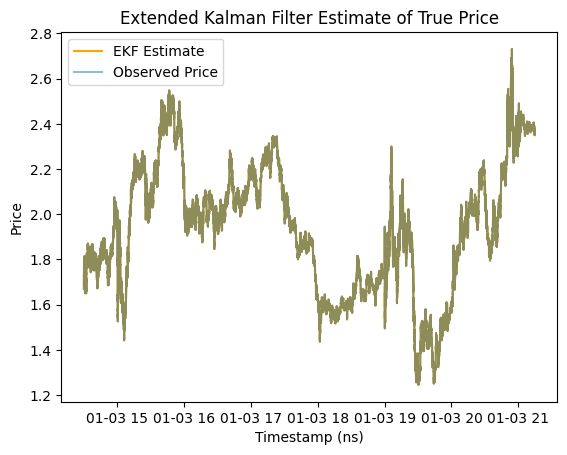

In [170]:
plt.plot(
    df_quotes_result["ts_ns"],
    df_quotes_result["kalman_price"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_quotes_result["ts_ns"], df_quotes_result["observed_price"], label="Observed Price", alpha=0.5
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

In [171]:
df_trades_result

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,kalman_prior,trade_residual
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.424 EST,"""trade""",1.67,0.13,1.67,1.8,null,null,0.001056,1.75875,-0.08875
2024-01-03 09:30:00.472 EST,"""trade""",1.69,0.16,1.64,1.8,null,null,0.0016,1.750479,-0.060479
2024-01-03 09:30:00.576 EST,"""trade""",1.7,0.02,1.7,1.72,null,null,0.000025,1.711489,-0.011489
2024-01-03 09:30:00.617 EST,"""trade""",1.71,0.02,1.7,1.72,null,null,0.000025,1.711489,-0.001489
2024-01-03 09:30:01.480 EST,"""trade""",1.71,0.02,1.7,1.72,null,null,0.000025,1.711491,-0.001491
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:11:20.628 EST,"""trade""",2.37,0.01,2.39,2.4,null,null,0.000006,2.394219,-0.024219
2024-01-03 16:11:20.628 EST,"""trade""",2.37,0.01,2.39,2.4,null,null,0.000006,2.394219,-0.024219
2024-01-03 16:12:51.108 EST,"""trade""",2.38,0.03,2.36,2.39,null,null,0.000056,2.373077,0.006923


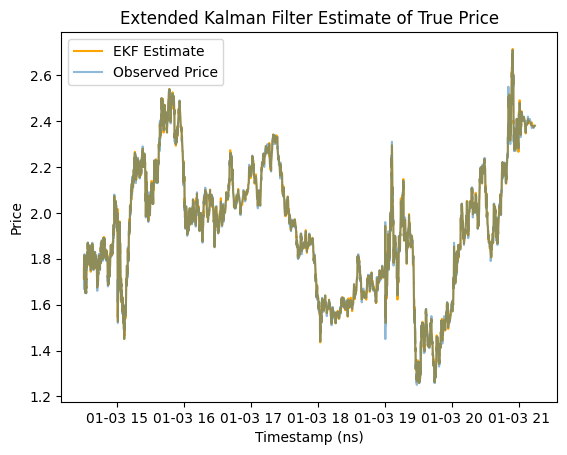

In [172]:
plt.plot(
    df_trades_result["ts_ns"],
    df_trades_result["kalman_prior"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_trades_result["ts_ns"], df_trades_result["observed_price"], label="Observed Price", alpha=0.5
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

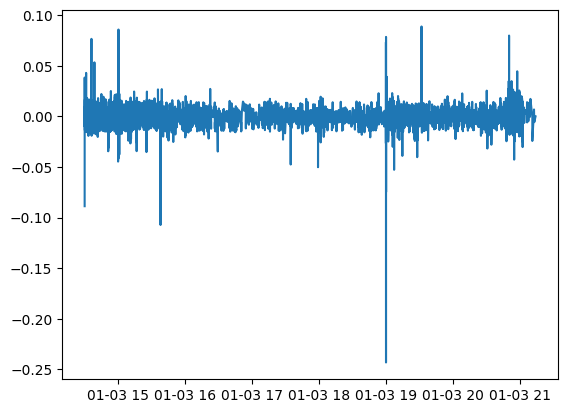

In [173]:
plt.plot(df_trades_result["ts_ns"], df_trades_result["trade_residual"])

In [174]:
df_trades_result.select((pl.col("trade_residual") ** 2).mean())

trade_residual
f64
0.000092


## NOW IMPLIED VOL

In [175]:
df_spy

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.003119872 EST,470.43,100.0,0
2024-01-03 09:30:00.021508608 EST,470.46,100.0,0
2024-01-03 09:30:00.021577984 EST,470.46,100.0,0
2024-01-03 09:30:00.033044224 EST,470.4301,741.0,0
2024-01-03 09:30:00.035522560 EST,470.46,100.0,0
…,…,…,…
2024-01-03 16:00:00.050740480 EST,468.74,300.0,0
2024-01-03 16:00:00.050803456 EST,468.74,400.0,0
2024-01-03 16:00:00.050809600 EST,468.74,100.0,0


In [176]:
df_events = df_events.join_asof(
    df_spy.select(["ts_ns", "price"]), on="ts_ns", strategy="backward"
).rename({"price": "spot"})

In [177]:
# import jax.numpy as jnp
# from jax.scipy.special import ndtr  # fast normal CDF


# def bs_call_price(S, K, T, r, sigma):
#     sqrtT = jnp.sqrt(T)
#     d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
#     d2 = d1 - sigma * sqrtT
#     return S * ndtr(d1) - K * jnp.exp(-r * T) * ndtr(d2)


# def bs_vega(S, K, T, r, sigma):
#     sqrtT = jnp.sqrt(T)
#     d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
#     pdf = jnp.exp(-0.5 * d1**2) / jnp.sqrt(2 * jnp.pi)
#     return S * sqrtT * pdf


# @jax.jit
# def implied_vol_batch(price, S, K, T, r, n_iter=20):
#     sigma = jnp.full_like(price, 0.2)

#     def step(_, sigma):
#         model = bs_call_price(S, K, T, r, sigma)
#         vega = bs_vega(S, K, T, r, sigma)
#         sigma = sigma - (model - price) / jnp.maximum(vega, 1e-8)
#         return jnp.clip(sigma, 1e-4, 5.0)

#     sigma = jax.lax.fori_loop(0, n_iter, step, sigma)
#     return sigma

In [178]:
from functools import partial

import jax
import jax.numpy as jnp
import polars as pl


# --- Black-Scholes price & vega ---
@jax.jit
def bs_call_price(S, K, T, r, sigma):
    d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * jnp.sqrt(T))
    d2 = d1 - sigma * jnp.sqrt(T)
    norm = jax.scipy.stats.norm
    return S * norm.cdf(d1) - K * jnp.exp(-r * T) * norm.cdf(d2)


@jax.jit
def bs_vega(S, K, T, r, sigma):
    d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * jnp.sqrt(T))
    return S * jax.scipy.stats.norm.pdf(d1) * jnp.sqrt(T)


# --- Single Newton-Raphson step ---
@jax.jit
def newton_iv(market_price, S, K, T, r, max_iter=10):
    sigma = jnp.full_like(market_price, 0.3)  # initial guess

    def step(sigma, _):
        price = bs_call_price(S, K, T, r, sigma)
        vega = bs_vega(S, K, T, r, sigma)
        # Clip vega to avoid div-by-zero
        return sigma - (price - market_price) / jnp.where(vega < 1e-8, 1e-8, vega), None

    sigma, _ = jax.lax.scan(step, sigma, None, length=max_iter)
    return sigma

In [179]:
df_events.select(pl.col("ts_ns"))

ts_ns
"datetime[ns, America/New_York]"
2024-01-03 09:30:00.183667200 EST
2024-01-03 09:30:00.217322240 EST
2024-01-03 09:30:00.383298048 EST
2024-01-03 09:30:00.400694528 EST
2024-01-03 09:30:00.419033088 EST
…
2024-01-03 16:14:42.406433024 EST
2024-01-03 16:14:42.450262016 EST
2024-01-03 16:14:54.333178624 EST


In [180]:
# Expiry: next day at 16:00 ET (standard US equity options close)
expiry = datetime(2024, 1, 4, 16, 0, 0, tzinfo=pytz.timezone("America/New_York"))

df_events = df_events.with_columns(
    [
        (
            (pl.lit(expiry) - pl.col("ts_ns")).dt.total_nanoseconds() / (365.25 * 24 * 3600 * 1e9)
        ).alias("T")
    ]
)

In [181]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,spot,T
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,470.45,0.003479
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,470.45,0.003479
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,470.46,0.003479
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,470.46,0.003479
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,470.46,0.003479
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,468.74,0.00271
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,468.74,0.00271
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,468.74,0.00271


In [182]:
# Extract as JAX arrays (zero-copy via numpy)
price = jnp.array(df_events["observed_price"].to_numpy())
S = jnp.array(df_events["spot"].to_numpy())
K = jnp.full_like(price, 470.0)  # hardcoded strike for this contract
T = jnp.array(df_events["T"].to_numpy())  # time to expiry in years
r = jnp.full_like(price, 0.0)  # assume 0 for intraday changes

iv = newton_iv(price, S, K, T, r)

# Write back
df_events = df_events.with_columns(pl.Series("iv", iv.tolist()))

In [183]:
bid_price = jnp.array(df_events["bid_price"].to_numpy())
ask_price = jnp.array(df_events["ask_price"].to_numpy())
bid_iv = newton_iv(bid_price, S, K, T, r)
ask_iv = newton_iv(ask_price, S, K, T, r)
df_events = df_events.with_columns(
    [
        pl.Series("bid_iv", bid_iv.tolist()),
        pl.Series("ask_iv", ask_iv.tolist()),
    ]
)

In [184]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,spot,T,iv,bid_iv,ask_iv
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,470.45,0.003479,0.135038,0.133215,0.136859
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,470.45,0.003479,0.135038,0.134127,0.135948
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,470.46,0.003479,0.134535,0.132715,0.136359
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,470.46,0.003479,0.131422,0.130897,0.140908
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,470.46,0.003479,0.137236,0.129072,0.140908
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,468.74,0.00271,0.301807,0.301316,0.303399
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,468.74,0.00271,0.301952,0.301314,0.303398
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,468.74,0.00271,0.303834,0.302378,0.30446


In [185]:
df_events = df_events.with_columns(
    (
        pl.col("R")
        * (((pl.col("ask_iv") - pl.col("bid_iv")) / 2) ** 2)
        / ((pl.col("spread") / 2) ** 2)
    ).alias("R_iv")
)

In [186]:
df_events = df_events.rename({"iv": "observed_iv"})

In [187]:
df_events = df_events.with_columns(
    ((((pl.col("ask_iv") - pl.col("bid_iv")) * 100) / 2) ** 2).alias("R_iv")
).with_columns(
    pl.when(pl.col("event_type") == "trade")
    .then(pl.col("R_iv").fill_null(strategy="forward") / TRADE_R_DIVISOR)
    .otherwise(pl.col("R_iv"))
    .alias("R_iv")
)

In [188]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,spot,T,observed_iv,bid_iv,ask_iv,R_iv
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,470.45,0.003479,0.135038,0.133215,0.136859,0.03319
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,470.45,0.003479,0.135038,0.134127,0.135948,0.008293
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,470.46,0.003479,0.134535,0.132715,0.136359,0.033199
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,470.46,0.003479,0.131422,0.130897,0.140908,0.250582
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,470.46,0.003479,0.137236,0.129072,0.140908,0.350229
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,468.74,0.00271,0.301807,0.301316,0.303399,0.010855
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,468.74,0.00271,0.301952,0.301314,0.303398,0.010853
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,468.74,0.00271,0.303834,0.302378,0.30446,0.010847


## KF on IV

In [189]:
def f(x):
    return x


def h(x):
    return x


def ekf_step(x, P, z, R_scalar, Q):
    F = jax.jacrev(f)(x)
    x_pred = f(x)
    P_pred = F @ P @ F.T + Q

    H = jax.jacrev(h)(x_pred)
    y = z - h(x_pred)
    S = H @ P_pred @ H.T + R_scalar
    K_T = jnp.linalg.solve(S, H @ P_pred)
    K = K_T.T

    x_new = x_pred + K @ y
    I = jnp.eye(x.shape[0], dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred
    return x_new, P_new


@jax.jit
def run_ekf(prices, Rs):
    x0 = jnp.array([prices[0]], dtype=jnp.float32)
    P0 = jnp.array([[1.0]], dtype=jnp.float32)
    Q = jnp.array([[0.01]], dtype=jnp.float32)

    def scan_step(carry, obs):
        x, P = carry
        price, R_scalar = obs
        z = jnp.array([price], dtype=jnp.float32)
        R = jnp.array([[R_scalar]], dtype=jnp.float32)
        x_new, P_new = ekf_step(x, P, z, R, Q)
        return (x_new, P_new), x_new[0]

    (_, _), estimates = jax.lax.scan(scan_step, (x0, P0), (prices, Rs))
    return estimates


def estimate_true_iv(df_events: pl.DataFrame) -> pl.DataFrame:
    prices = jnp.array(df_events["observed_iv"].to_numpy(), dtype=jnp.float32)
    Rs = jnp.array(df_events["R_iv"].to_numpy(), dtype=jnp.float32)

    estimates = run_ekf(prices, Rs)

    return df_events.with_columns(
        pl.Series(name="kalman_iv", values=jax.device_get(estimates).tolist())
    )


# Usage
# df_result = estimate_true_iv(df_events)

In [190]:
# ── STEP 1: Train the Kalman filter on quotes only ───────────────────────────
df_iv_quotes_only = df_events.filter(pl.col("event_type") == "quote")

prices_train = jnp.array(df_iv_quotes_only["observed_price"].to_numpy(), dtype=jnp.float32)
Rs_train = jnp.array(df_iv_quotes_only["R"].to_numpy(), dtype=jnp.float32)

estimates_train = run_ekf(prices_train, Rs_train)

df_iv_quotes_result = df_iv_quotes_only.with_columns(
    pl.Series("kalman_price", jax.device_get(estimates_train).tolist())
)

# ── STEP 2: Test on trades ────────────────────────────────────────────────────
# For each trade, get the Kalman estimate from the most recent preceding quote.
# This is a pure out-of-sample evaluation: the filter never saw trades.

df_iv_trades_only = df_events.filter(pl.col("event_type") == "trade")

df_iv_trades_result = df_iv_trades_only.join_asof(
    df_iv_quotes_result.select(["ts_ns", "kalman_price"]).rename({"kalman_price": "kalman_prior"}),
    on="ts_ns",
    strategy="backward",
)

# Residual: how far is the trade price from the filter's quote-derived estimate?
df_iv_trades_result = df_iv_trades_result.with_columns(
    (pl.col("observed_price") - pl.col("kalman_prior")).alias("trade_residual")
)

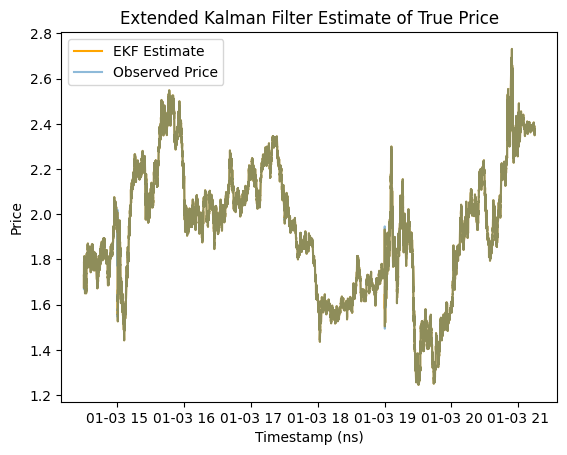

In [195]:
plt.plot(
    df_iv_quotes_result["ts_ns"],
    df_iv_quotes_result["kalman_price"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_iv_quotes_result["ts_ns"],
    df_iv_quotes_result["observed_price"],
    label="Observed Price",
    alpha=0.5,
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

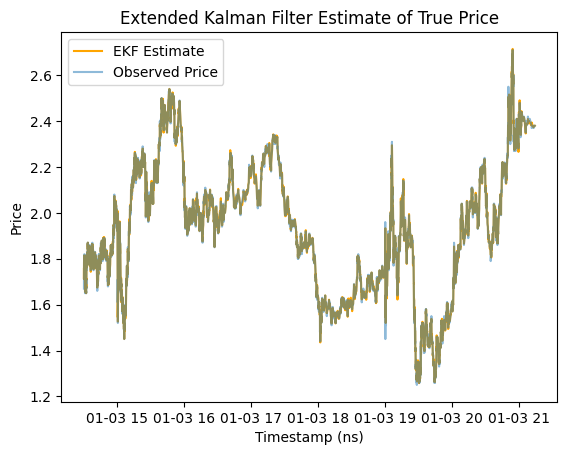

In [196]:
plt.plot(
    df_iv_trades_result["ts_ns"],
    df_iv_trades_result["kalman_prior"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_iv_trades_result["ts_ns"],
    df_iv_trades_result["observed_price"],
    label="Observed Price",
    alpha=0.5,
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

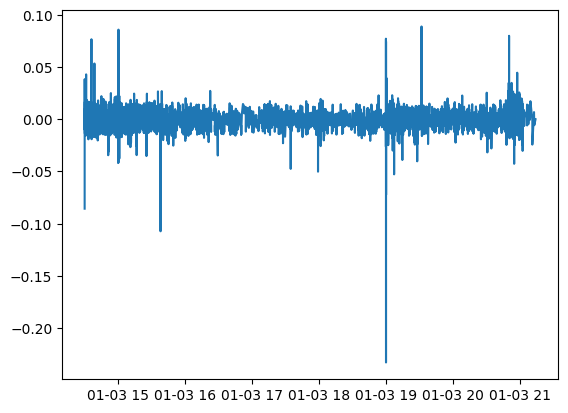

In [197]:
plt.plot(df_iv_trades_result["ts_ns"], df_iv_trades_result["trade_residual"])

In [198]:
df_iv_trades_result.select((pl.col("trade_residual") ** 2).mean())

trade_residual
f64
0.000091


comparison

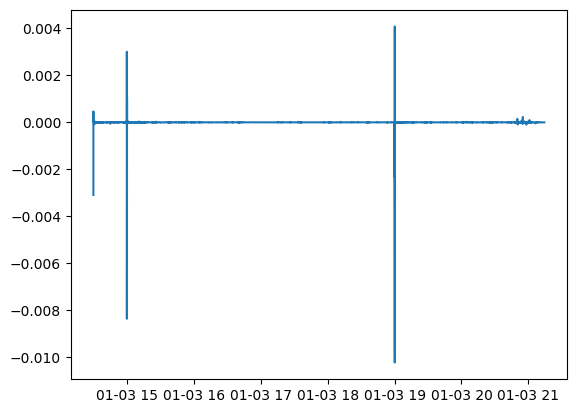

In [200]:
plt.plot(
    df_trades_result["ts_ns"],
    df_trades_result["trade_residual"] - df_iv_trades_result["trade_residual"],
)

In [203]:
diff = df_trades_result["trade_residual"] - df_iv_trades_result["trade_residual"]

In [204]:
diff.abs().mean()

1.6910377146488765e-05

In [205]:
diff.abs().max()

0.010219693183898926

In [208]:
diff.shape

(8895,)

In [207]:
(diff.abs() > 0.0001).sum()

62